In [1]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"

job_skills = pd.read_csv(
    RAW_DIR / "jobs" / "job_skills.csv"
)

skills = pd.read_csv(
    RAW_DIR / "mappings" / "skills.csv"
)

print("Job skills shape:", job_skills.shape)
print("Skills mapping shape:", skills.shape)

print("\nJob skills columns:")
print(job_skills.columns.tolist())

print("\nSkills mapping columns:")
print(skills.columns.tolist())

display(job_skills.head())
display(skills.head())

Job skills shape: (213768, 2)
Skills mapping shape: (35, 2)

Job skills columns:
['job_id', 'skill_abr']

Skills mapping columns:
['skill_abr', 'skill_name']


,job_id,skill_abr
0,3884428798,MRKT
1,3884428798,PR
2,3884428798,WRT
3,3887473071,SALE
4,3887465684,FIN


,skill_abr,skill_name
0,ART,Art/Creative
1,DSGN,Design
2,ADVR,Advertising
3,PRDM,Product Management
4,DIST,Distribution


Step 1 — Understand the relationship


             job_skills.csv
           job_id · skill_abr

Which skills are associated with each job?

            Join using skill_abr

                skills.csv
            
        skill_abr · skill_name

What does each skill abbreviation mean?

Step 2 — Merge the skill files

In [2]:
# Merge job skills with readable skill names
job_skills_named = job_skills.merge(
    skills,
    on="skill_abr",
    how="left",
    validate="many_to_one"
)

print("Merged shape:", job_skills_named.shape)

display(job_skills_named.head(10))

Merged shape: (213768, 3)


,job_id,skill_abr,skill_name
0,3884428798,MRKT,Marketing
1,3884428798,PR,Public Relations
2,3884428798,WRT,Writing/Editing
3,3887473071,SALE,Sales
4,3887465684,FIN,Finance
5,3887465684,SALE,Sales
6,3887467939,SALE,Sales
7,3887467939,ADVR,Advertising
8,3887467939,BD,Business Development
9,3887471331,ENG,Engineering


Step 3 — Find the most common skill categories

In [3]:
skill_counts = (
    job_skills_named["skill_name"]
    .value_counts()
    .head(15)
)

print(skill_counts)

skill_name
Information Technology    26137
Sales                     22475
Management                20861
Manufacturing             18185
Health Care Provider      17369
Business Development      14290
Engineering               13009
Other                     12608
Finance                    8540
Marketing                  5525
Accounting/Auditing        5461
Administrative             4860
Customer Service           4292
Project Management         3997
Analyst                    3858
Name: count, dtype: int64


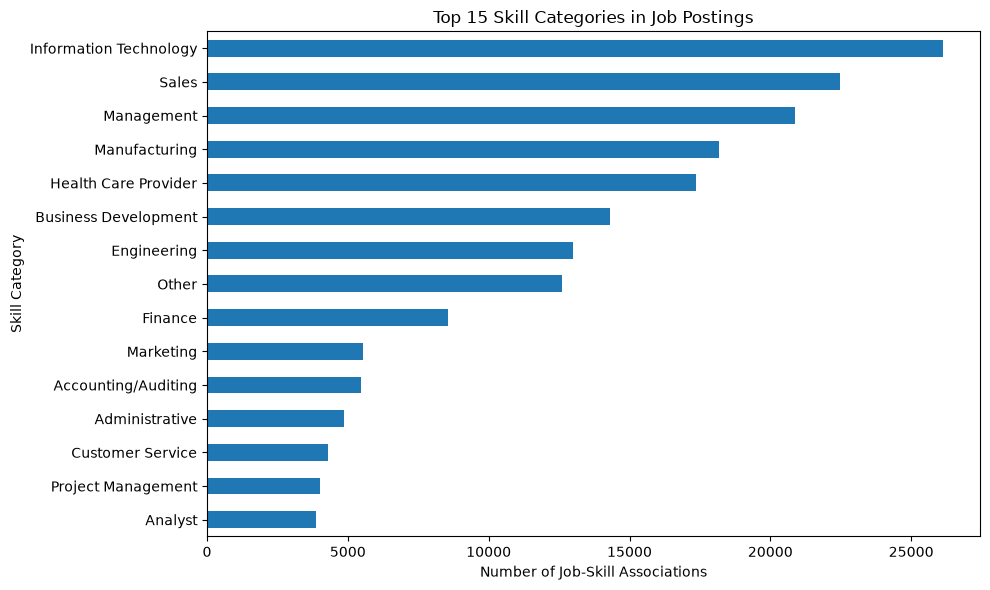

In [4]:
import matplotlib.pyplot as plt

skill_counts.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 15 Skill Categories in Job Postings")
plt.xlabel("Number of Job-Skill Associations")
plt.ylabel("Skill Category")
plt.tight_layout()
plt.show()

In [5]:
# Load only the columns needed from job postings
postings_small = pd.read_csv(
    RAW_DIR / "postings.csv",
    usecols=["job_id", "title"]
)

# Connect skills with job titles
skills_with_titles = job_skills_named.merge(
    postings_small,
    on="job_id",
    how="left",
    validate="many_to_one"
)

print("Merged shape:", skills_with_titles.shape)
display(skills_with_titles.head())

Merged shape: (213768, 4)


,job_id,skill_abr,skill_name,title
0,3884428798,MRKT,Marketing,Public Relations Intern
1,3884428798,PR,Public Relations,Public Relations Intern
2,3884428798,WRT,Writing/Editing,Public Relations Intern
3,3887473071,SALE,Sales,Outside Sales Consultant
4,3887465684,FIN,Finance,Seasonal Teller Trainee - Montgomery County( H...


In [6]:
data_scientist_skills = skills_with_titles[
    skills_with_titles["title"].str.contains(
        "Data Scientist",
        case=False,
        na=False
    )
]

print("Job-skill associations:", len(data_scientist_skills))

display(
    data_scientist_skills["skill_name"]
    .value_counts()
    .head(15)
)

Job-skill associations: 452


skill_name
Information Technology    196
Engineering               166
Analyst                    22
Other                      17
Research                    9
Science                     8
Consulting                  7
Finance                     4
Sales                       3
Product Management          3
Management                  3
Strategy/Planning           3
General Business            2
Business Development        2
Project Management          2
Name: count, dtype: int64

Compare three job roles

In [7]:
roles = {
    "Data Scientist": "Data Scientist",
    "Data Analyst": "Data Analyst",
    "Machine Learning Engineer": "Machine Learning Engineer"
}

for role, keyword in roles.items():

    role_data = skills_with_titles[
        skills_with_titles["title"].str.contains(
            keyword,
            case=False,
            na=False
        )
    ]

    print(f"\n--- {role} ---")
    print("Job-skill associations:", len(role_data))

    display(
        role_data["skill_name"]
        .value_counts()
        .head(10)
    )


--- Data Scientist ---
Job-skill associations: 452


skill_name
Information Technology    196
Engineering               166
Analyst                    22
Other                      17
Research                    9
Science                     8
Consulting                  7
Finance                     4
Sales                       3
Product Management          3
Name: count, dtype: int64


--- Data Analyst ---
Job-skill associations: 616


skill_name
Information Technology    287
Analyst                   138
Research                   58
Engineering                46
Other                      20
Finance                    12
Marketing                  10
Quality Assurance          10
Administrative              6
Business Development        5
Name: count, dtype: int64


--- Machine Learning Engineer ---
Job-skill associations: 167


skill_name
Engineering               72
Information Technology    71
Research                  11
Other                      3
Accounting/Auditing        1
Advertising                1
Administrative             1
Project Management         1
Analyst                    1
Quality Assurance          1
Name: count, dtype: int64

Create a technical skills dictionary

In [8]:
technical_skills = [
    "Python",
    "SQL",
    "Excel",
    "Power BI",
    "Tableau",
    "Pandas",
    "NumPy",
    "Matplotlib",
    "Seaborn",
    "Scikit-learn",
    "TensorFlow",
    "PyTorch",
    "Machine Learning",
    "Deep Learning",
    "Statistics",
    "Probability",
    "Data Visualization",
    "Data Analysis",
    "Natural Language Processing",
    "Large Language Models",
    "AWS",
    "Azure",
    "Docker",
    "Git",
    "Spark"
]

print("Skills in dictionary:", len(technical_skills))

Skills in dictionary: 25


Load descriptions for the relevant roles

In [9]:
import pandas as pd

role_keywords = (
    "data scientist|data analyst|machine learning engineer"
)

job_descriptions = pd.read_csv(
    RAW_DIR / "postings.csv",
    usecols=["job_id", "title", "description"]
)

job_descriptions = job_descriptions[
    job_descriptions["title"].str.contains(
        role_keywords,
        case=False,
        na=False
    )
].copy()

print("Relevant job postings:", len(job_descriptions))
print(job_descriptions[["title", "description"]].head())

Relevant job postings: 742
                                                  title  \
389                                        Data Analyst   
663                           Machine Learning Engineer   
670                              eCommerce Data Analyst   
1044            Wealth Management Business Data Analyst   
1277  Senior Data Analyst - AI Training (Remote, Con...   

                                            description  
389   Job Title: Data AnalystDuration: ContractLocat...  
663   Job Title: Python AI/ MLType: FulltimeLocation...  
670   Job Description: JOB SUMMARY:Responsible for c...  
1044  Job Title: BUSINESS DATA ANALYST Location: Aus...  
1277  Job Type: Contract\n\nWe don’t sponsor work vi...  


Extract skill mentions

In [10]:
import re

def extract_skills(description):
    if pd.isna(description):
        return []

    found = []

    for skill in technical_skills:
        pattern = r"(?<!\w)" + re.escape(skill) + r"(?!\w)"

        if re.search(pattern, description, flags=re.IGNORECASE):
            found.append(skill)

    return found


job_descriptions["extracted_skills"] = (
    job_descriptions["description"].apply(extract_skills)
)

display(
    job_descriptions[
        ["title", "extracted_skills"]
    ].head(10)
)

,title,extracted_skills
389,Data Analyst,"[Python, SQL, Statistics, Data Visualization]"
663,Machine Learning Engineer,"[Python, TensorFlow, PyTorch, AWS, Azure]"
670,eCommerce Data Analyst,[Data Analysis]
1044,Wealth Management Business Data Analyst,"[Python, SQL, Data Analysis, AWS]"
1277,"Senior Data Analyst - AI Training (Remote, Con...","[SQL, Excel, Data Analysis, Large Language Mod..."
1338,Data Scientist Job,"[Python, SQL, Tableau, Statistics]"
1755,Onsite Data Analyst || USC ONLY || FL LOCALS,[Data Analysis]
1814,Sr. Procurement Data Analyst,"[SQL, Excel, Data Analysis]"
2026,Design Data Analyst,[]
2098,Data Analyst - Expert with Excel,[Excel]


Calculate skill demand

In [11]:
from collections import Counter

skill_counts = Counter()

for skills_list in job_descriptions["extracted_skills"]:
    skill_counts.update(set(skills_list))

skill_demand = pd.DataFrame(
    skill_counts.items(),
    columns=["Skill", "Job_Count"]
)

skill_demand = skill_demand.sort_values(
    "Job_Count",
    ascending=False
).reset_index(drop=True)

skill_demand["Percentage"] = (
    skill_demand["Job_Count"]
    / len(job_descriptions) * 100
).round(2)

display(skill_demand)

,Skill,Job_Count,Percentage
0,Python,425,57.28
1,SQL,410,55.26
2,Machine Learning,312,42.05
3,Statistics,257,34.64
4,Data Analysis,254,34.23
5,Excel,167,22.51
6,Tableau,130,17.52
7,Data Visualization,125,16.85
8,AWS,114,15.36
9,PyTorch,82,11.05


Visualize the top 10 skills

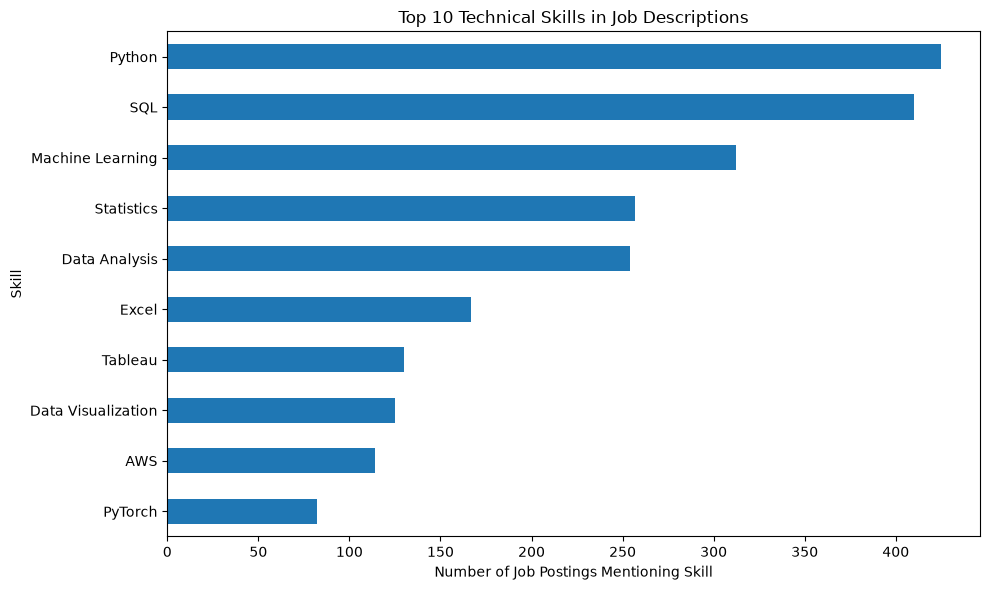

In [12]:
import matplotlib.pyplot as plt

top_skills = skill_demand.head(10).sort_values(
    "Job_Count"
)

top_skills.plot(
    x="Skill",
    y="Job_Count",
    kind="barh",
    legend=False,
    figsize=(10, 6)
)

plt.title("Top 10 Technical Skills in Job Descriptions")
plt.xlabel("Number of Job Postings Mentioning Skill")
plt.ylabel("Skill")
plt.tight_layout()
plt.show()

In [13]:

from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

role_patterns = {
    "Data Analyst": r"data analyst",
    "Data Scientist": r"data scientist",
    "Machine Learning Engineer": r"machine learning engineer"
}

role_results = []

for role, pattern in role_patterns.items():

    role_df = job_descriptions[
        job_descriptions["title"].str.contains(
            pattern, case=False, na=False
        )
    ]

    counts = Counter()

    for skills in role_df["extracted_skills"]:
        counts.update(set(skills))

    for skill, count in counts.items():
        role_results.append({
            "Role": role,
            "Skill": skill,
            "Job_Count": count,
            "Percentage": round(
                count / len(role_df) * 100, 2
            ) if len(role_df) > 0 else 0
        })

role_skill_demand = pd.DataFrame(role_results)

display(
    role_skill_demand.sort_values(
        ["Role", "Job_Count"],
        ascending=[True, False]
    )
)


,Role,Skill,Job_Count,Percentage
2,Data Analyst,SQL,246,60.29
7,Data Analyst,Excel,147,36.03
4,Data Analyst,Data Analysis,146,35.78
3,Data Analyst,Python,139,34.07
1,Data Analyst,Statistics,85,20.83
...,...,...,...,...
66,Machine Learning Engineer,Data Visualization,4,4.55
68,Machine Learning Engineer,Git,4,4.55
67,Machine Learning Engineer,Excel,3,3.41
70,Machine Learning Engineer,Power BI,2,2.27


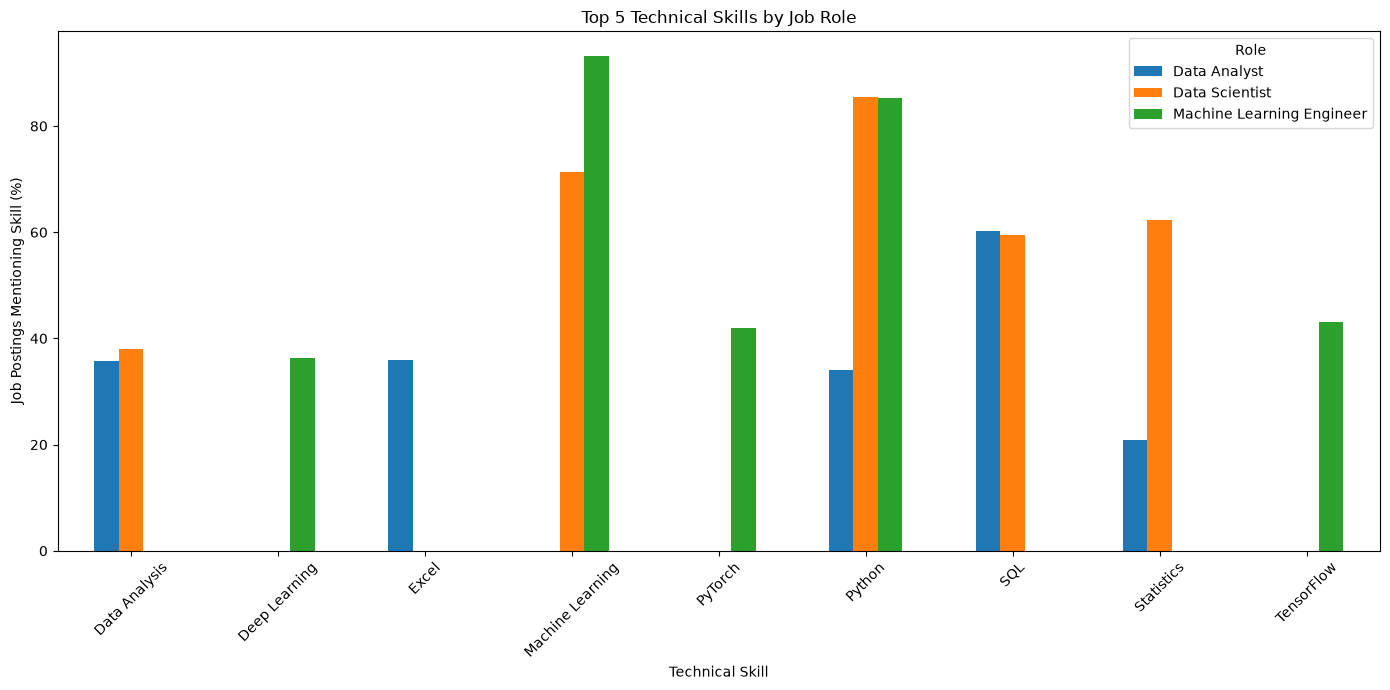

In [14]:

# Select the top 5 skills within each role
top_role_skills = (
    role_skill_demand
    .sort_values(["Role", "Job_Count"], ascending=[True, False])
    .groupby("Role")
    .head(5)
)

# Convert rows into a chart-friendly table
comparison = top_role_skills.pivot(
    index="Skill",
    columns="Role",
    values="Percentage"
)

# Plot comparison
ax = comparison.plot(
    kind="bar",
    figsize=(14, 7)
)

ax.set_title("Top 5 Technical Skills by Job Role")
ax.set_xlabel("Technical Skill")
ax.set_ylabel("Job Postings Mentioning Skill (%)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


Identify common and role-specific skills

In [15]:

# Count how many different roles mention each skill
skill_summary = (
    role_skill_demand
    .groupby("Skill")
    .agg(
        Roles_Count=("Role", "nunique"),
        Total_Job_Mentions=("Job_Count", "sum"),
        Average_Percentage=("Percentage", "mean")
    )
    .reset_index()
)

# Classify skills by how widely they appear across roles
skill_summary["Skill_Type"] = skill_summary["Roles_Count"].apply(
    lambda x: "Common Across Roles" if x == 3
    else "Shared Across Some Roles" if x == 2
    else "Role-Specific in This Sample"
)

skill_summary = skill_summary.sort_values(
    ["Roles_Count", "Total_Job_Mentions"],
    ascending=[False, False]
).reset_index(drop=True)

display(skill_summary)


,Skill,Roles_Count,Total_Job_Mentions,Average_Percentage,Skill_Type
0,Python,3,425,68.243333,Common Across Roles
1,SQL,3,411,46.750000,Common Across Roles
2,Machine Learning,3,312,59.226667,Common Across Roles
3,Statistics,3,258,34.923333,Common Across Roles
4,Data Analysis,3,254,29.916667,Common Across Roles
5,Excel,3,168,15.576667,Common Across Roles
6,Tableau,3,131,13.450000,Common Across Roles
7,Data Visualization,3,125,14.120000,Common Across Roles
8,AWS,3,114,19.290000,Common Across Roles
9,Deep Learning,3,82,18.816667,Common Across Roles


Visualize the result

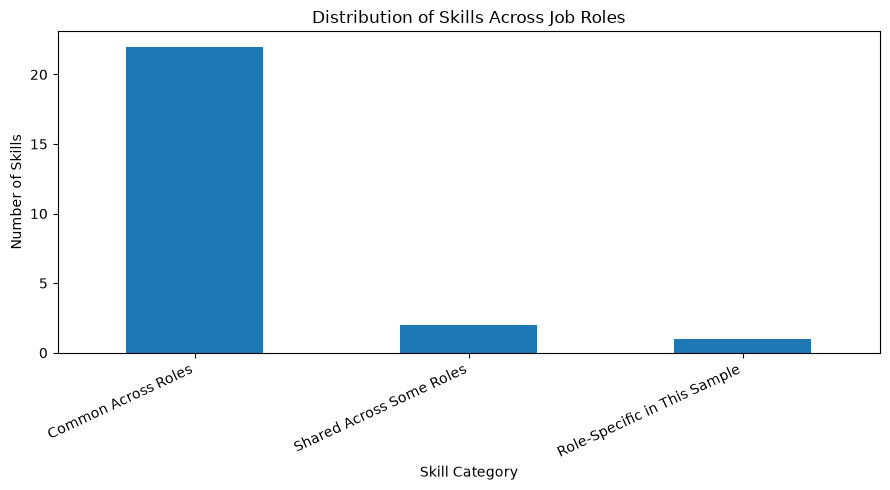

In [16]:

import matplotlib.pyplot as plt

skill_type_counts = skill_summary["Skill_Type"].value_counts()

skill_type_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Distribution of Skills Across Job Roles")
plt.xlabel("Skill Category")
plt.ylabel("Number of Skills")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


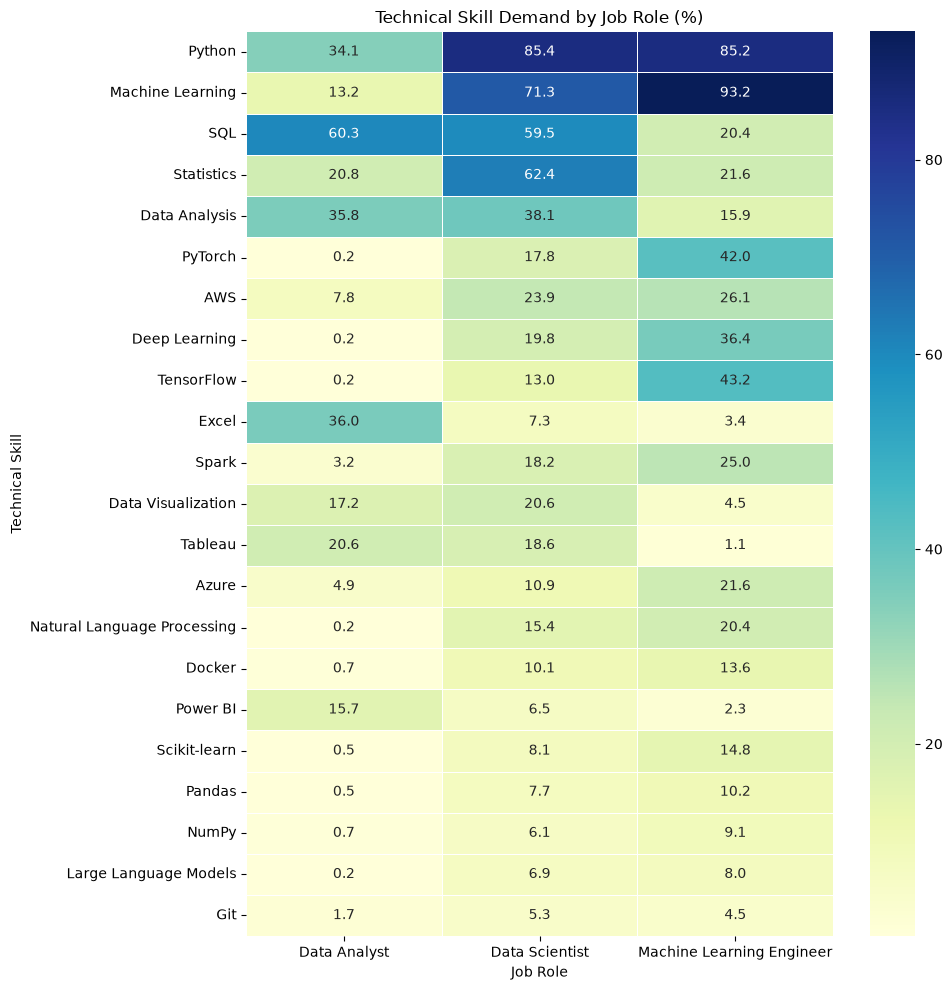

In [18]:

import matplotlib.pyplot as plt
import seaborn as sns

# Keep skills appearing in all three role groups
common_skills = skill_summary.loc[
    skill_summary["Roles_Count"] == 3, "Skill"
].tolist()

# Prepare role-wise percentages for the heatmap
heatmap_data = (
    role_skill_demand[
        role_skill_demand["Skill"].isin(common_skills)
    ]
    .pivot(index="Skill", columns="Role", values="Percentage")
    .fillna(0)
)

# Sort by average percentage across roles
heatmap_data = heatmap_data.loc[
    heatmap_data.mean(axis=1).sort_values(ascending=False).index
]

plt.figure(figsize=(10, 10))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Technical Skill Demand by Job Role (%)")
plt.xlabel("Job Role")
plt.ylabel("Technical Skill")
plt.tight_layout()
plt.show()


In [19]:

# Verify how many postings were selected for each role
for role, pattern in role_patterns.items():
    role_df = job_descriptions[
        job_descriptions["title"].str.contains(
            pattern, case=False, na=False
        )
    ]

    print(f"{role}: {len(role_df)} postings")

# Check the underlying counts for selected skills
display(
    role_skill_demand[
        role_skill_demand["Skill"].isin(
            ["Python", "SQL", "Machine Learning", "TensorFlow", "PyTorch"]
        )
    ].sort_values(["Role", "Job_Count"], ascending=[True, False])
)


Data Analyst: 408 postings
Data Scientist: 247 postings
Machine Learning Engineer: 88 postings


,Role,Skill,Job_Count,Percentage
2,Data Analyst,SQL,246,60.29
3,Data Analyst,Python,139,34.07
9,Data Analyst,Machine Learning,54,13.24
12,Data Analyst,TensorFlow,1,0.25
13,Data Analyst,PyTorch,1,0.25
27,Data Scientist,Python,211,85.43
28,Data Scientist,Machine Learning,176,71.26
26,Data Scientist,SQL,147,59.51
36,Data Scientist,PyTorch,44,17.81
34,Data Scientist,TensorFlow,32,12.96


In [22]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(r"D:\project\DS\Job Market & Salary Analysis project")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

df = pd.read_csv(PROCESSED_DIR / "job_postings_flagged.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)


Dataset loaded successfully!
Shape: (123849, 32)


In [23]:

salary_columns = [
    "min_salary",
    "max_salary",
    "med_salary",
    "normalized_salary"
]

print("Total job postings:", len(df))

salary_available = df[salary_columns].notna().any(axis=1).sum()
print("Postings with any salary:", salary_available)

print("\nPay-period distribution:")

display(
    df["pay_period"]
    .value_counts(dropna=False)
    .rename_axis("Pay_Period")
    .reset_index(name="Job_Count")
)


Total job postings: 123849
Postings with any salary: 36073

Pay-period distribution:


,Pay_Period,Job_Count
0,NaN,87776
1,YEARLY,20628
2,HOURLY,14741
3,MONTHLY,518
4,WEEKLY,177
5,BIWEEKLY,9


Analyze salary quality

In [24]:

# Inspect salary columns
salary_columns = [
    "min_salary",
    "max_salary",
    "med_salary",
    "normalized_salary"
]

display(df[salary_columns].describe().round(2))

# Count missing values in salary columns
display(
    df[salary_columns]
    .isna()
    .sum()
    .rename("Missing_Count")
    .to_frame()
)

# Check for negative salary values
for col in salary_columns:
    print(f"{col}: {(df[col] < 0).sum()} negative values")

# Check whether minimum salary exceeds maximum salary
invalid_range = (
    df["min_salary"].notna()
    & df["max_salary"].notna()
    & (df["min_salary"] > df["max_salary"])
)

print("Minimum salary greater than maximum:", invalid_range.sum())


,min_salary,max_salary,med_salary,normalized_salary
count,29793.00,2.979300e+04,6280.00,3.607300e+04
mean,64910.85,9.193942e+04,22015.62,2.053270e+05
std,495973.79,7.011101e+05,52255.87,5.097627e+06
min,1.00,1.000000e+00,0.00,0.000000e+00
25%,37.00,4.828000e+01,18.94,5.200000e+04
50%,60000.00,8.000000e+04,25.50,8.150000e+04
75%,100000.00,1.400000e+05,2510.50,1.250000e+05
max,85000000.00,1.200000e+08,750000.00,5.356000e+08


,Missing_Count
min_salary,94056
max_salary,94056
med_salary,117569
normalized_salary,87776


min_salary: 0 negative values
max_salary: 0 negative values
med_salary: 0 negative values
normalized_salary: 0 negative values
Minimum salary greater than maximum: 0


In [25]:

# Inspect the 10 highest normalized salaries
salary_check_columns = [
    "title",
    "company_name",
    "pay_period",
    "currency",
    "min_salary",
    "max_salary",
    "med_salary",
    "normalized_salary"
]

top_salary_records = (
    df.loc[df["normalized_salary"].notna(), salary_check_columns]
    .sort_values("normalized_salary", ascending=False)
    .head(10)
)

display(top_salary_records)


,title,company_name,pay_period,currency,min_salary,max_salary,med_salary,normalized_salary
9237,Intellectual Property Associate (246215),Eastridge Workforce Solutions,HOURLY,USD,240000.0,275000.0,NaN,535600000.0
98888,"Case Manager RN, Pedi Rheumatology",Kaiser Permanente,HOURLY,USD,151900.0,196570.0,NaN,362408800.0
13614,Cloud Domain Architect,Applicantz,HOURLY,USD,125000.0,150000.0,NaN,286000000.0
89082,Cloud Domain Architect,Applicantz,HOURLY,USD,125000.0,150000.0,NaN,286000000.0
60038,Billing Supervisor (246521),Eastridge Workforce Solutions,HOURLY,USD,125000.0,125000.0,NaN,260000000.0
102481,Manager - Clinical Applications Support - Anci...,Lakeland Regional Health-Florida,HOURLY,USD,98467.0,123094.0,NaN,230423440.0
71845,Sharepoint Developer,"DigiDoc, Inc. dba Public Sector Solutions Group",HOURLY,USD,100000.0,120000.0,NaN,228800000.0
72585,Trial Paralegal - Hybrid in OC or LA!,Adams & Martin Group,HOURLY,USD,80000.0,100000.0,NaN,187200000.0
17646,DCS Technician,Jobot,HOURLY,USD,70000.0,80000.0,NaN,156000000.0
87241,Full Time Field Service Technician – Anaheim/P...,The Hillman Group,HOURLY,USD,62000.0,68000.0,NaN,135200000.0


In [26]:

# Salary distribution by pay period
salary_by_period = (
    df[df["normalized_salary"].notna()]
    .groupby("pay_period", dropna=False)["normalized_salary"]
    .agg(["count", "median", "mean", "max"])
    .round(2)
    .sort_values("median", ascending=False)
)

display(salary_by_period)


,count,median,mean,max
pay_period,,,,
BIWEEKLY,9,1572805.0,1248661.56,2096744.0
WEEKLY,177,109148.0,111559.91,210548.0
YEARLY,20628,102000.0,119684.74,102500000.0
MONTHLY,518,53634.0,64082.72,1200000.0
HOURLY,14741,52520.0,330623.87,535600000.0


In [27]:

# Inspect hourly records with unusually high normalized salaries
hourly = df[df["pay_period"] == "HOURLY"].copy()

display(
    hourly.loc[
        hourly["normalized_salary"] > 1_000_000,
        [
            "title",
            "currency",
            "min_salary",
            "max_salary",
            "pay_period",
            "normalized_salary"
        ]
    ].sort_values("normalized_salary", ascending=False).head(20)
)


,title,currency,min_salary,max_salary,pay_period,normalized_salary
9237,Intellectual Property Associate (246215),USD,240000.0,275000.0,HOURLY,535600000.0
98888,"Case Manager RN, Pedi Rheumatology",USD,151900.0,196570.0,HOURLY,362408800.0
89082,Cloud Domain Architect,USD,125000.0,150000.0,HOURLY,286000000.0
13614,Cloud Domain Architect,USD,125000.0,150000.0,HOURLY,286000000.0
60038,Billing Supervisor (246521),USD,125000.0,125000.0,HOURLY,260000000.0
102481,Manager - Clinical Applications Support - Anci...,USD,98467.0,123094.0,HOURLY,230423440.0
71845,Sharepoint Developer,USD,100000.0,120000.0,HOURLY,228800000.0
72585,Trial Paralegal - Hybrid in OC or LA!,USD,80000.0,100000.0,HOURLY,187200000.0
17646,DCS Technician,USD,70000.0,80000.0,HOURLY,156000000.0
87241,Full Time Field Service Technician – Anaheim/P...,USD,62000.0,68000.0,HOURLY,135200000.0


In [28]:

# Compare original salary ranges by pay period
salary_range_check = (
    df[df["pay_period"].notna()]
    .groupby("pay_period")
    .agg(
        Postings=("job_id", "count"),
        Median_Min=("min_salary", "median"),
        Median_Max=("max_salary", "median"),
        Max_Min=("min_salary", "max"),
        Max_Max=("max_salary", "max")
    )
    .round(2)
)

display(salary_range_check)


,Postings,Median_Min,Median_Max,Max_Min,Max_Max
pay_period,,,,,
BIWEEKLY,9,54009.0,66976.0,71323.0,89965.0
HOURLY,14741,25.0,32.0,240000.0,275000.0
MONTHLY,518,5550.0,7350.0,90000.0,110000.0
WEEKLY,177,2099.0,2099.0,4049.0,4049.0
YEARLY,20628,87000.0,120000.0,85000000.0,120000000.0


In [29]:

# Flag unusually high raw salary values by pay period
df["salary_review_flag"] = False

# These are review thresholds, not universal salary limits
review_thresholds = {
    "HOURLY": 1000,
    "WEEKLY": 100000,
    "BIWEEKLY": 200000,
    "MONTHLY": 200000,
    "YEARLY": 1000000
}

for period, threshold in review_thresholds.items():
    mask = (
        (df["pay_period"] == period)
        & (
            (df["min_salary"] > threshold)
            | (df["max_salary"] > threshold)
        )
    )

    df.loc[mask, "salary_review_flag"] = True

print("Records flagged for salary review:",
      df["salary_review_flag"].sum())

display(
    df.loc[
        df["salary_review_flag"],
        [
            "title", "pay_period", "min_salary",
            "max_salary", "normalized_salary"
        ]
    ].head(10)
)


Records flagged for salary review: 40


,title,pay_period,min_salary,max_salary,normalized_salary
4735,Partner (& Groups w/ Portable Business for Top...,YEARLY,350000.0,1500000.0,925000.0
4781,Partner (& Groups w/ Portable Business for Top...,YEARLY,350000.0,1500000.0,925000.0
4908,Partner (& Groups w/ Portable Business for Top...,YEARLY,350000.0,1500000.0,925000.0
9237,Intellectual Property Associate (246215),HOURLY,240000.0,275000.0,535600000.0
13614,Cloud Domain Architect,HOURLY,125000.0,150000.0,286000000.0
17646,DCS Technician,HOURLY,70000.0,80000.0,156000000.0
19869,Full Time Field Service Technician – Wilmingto...,HOURLY,45000.0,50000.0,98800000.0
19991,"Full Time Field Service Technician – Tulsa, OK",HOURLY,42000.0,45000.0,90480000.0
34903,Technical Lab Specialist,YEARLY,77000.0,1115000.0,596000.0
40101,Data Engineer,HOURLY,65.0,6570.0,6900400.0


In [30]:

annual_salary = df[
    (df["pay_period"] == "YEARLY")
    & (df["currency"] == "USD")
    & df["min_salary"].notna()
    & df["max_salary"].notna()
    & (df["min_salary"] >= 0)
    & (df["max_salary"] >= df["min_salary"])
    & (df["max_salary"] <= 1_000_000)
].copy()

annual_salary["salary_midpoint"] = (
    annual_salary["min_salary"] + annual_salary["max_salary"]
) / 2

print("Yearly USD postings retained:", len(annual_salary))

display(
    annual_salary["salary_midpoint"]
    .describe()
    .round(2)
)


Yearly USD postings retained: 19084


count     19084.00
mean     116350.46
std       63070.20
min           1.00
25%       75000.00
50%      105000.00
75%      144925.00
max      875000.00
Name: salary_midpoint, dtype: float64

In [31]:

# Calculate IQR boundaries
Q1 = annual_salary["salary_midpoint"].quantile(0.25)
Q3 = annual_salary["salary_midpoint"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

# Flag statistical outliers
annual_salary["salary_outlier_flag"] = (
    (annual_salary["salary_midpoint"] < lower_bound)
    | (annual_salary["salary_midpoint"] > upper_bound)
)

print(
    "Potential outliers:",
    annual_salary["salary_outlier_flag"].sum()
)

display(
    annual_salary.loc[
        annual_salary["salary_outlier_flag"],
        ["title", "min_salary", "max_salary", "salary_midpoint"]
    ].sort_values("salary_midpoint", ascending=False).head(15)
)


Q1: 75000.0
Q3: 144925.0
IQR: 69925.0
Lower bound: -29887.5
Upper bound: 249812.5
Potential outliers: 622


,title,min_salary,max_salary,salary_midpoint
113069,Head of Front Office Technology,750000.0,1000000.0,875000.0
117057,Quantitative Researcher,650000.0,1000000.0,825000.0
73176,Litigation Partner,500000.0,1000000.0,750000.0
73491,Intellectual Property Partner,500000.0,1000000.0,750000.0
115087,Network Engineer,750000.0,750000.0,750000.0
115360,Python Developer,750000.0,750000.0,750000.0
118302,Senior Software Engineer,500000.0,1000000.0,750000.0
73329,Labor & Employment Partner,500000.0,1000000.0,750000.0
73461,Trust and Estates Partner,500000.0,1000000.0,750000.0
95097,Oral Surgeon,600000.0,800000.0,700000.0


In [32]:

outliers = annual_salary[
    annual_salary["salary_outlier_flag"]
].copy()

display(
    outliers[
        [
            "title",
            "company_name",
            "min_salary",
            "max_salary",
            "salary_midpoint"
        ]
    ]
    .sort_values("salary_midpoint", ascending=False)
    .head(15)
)


,title,company_name,min_salary,max_salary,salary_midpoint
113069,Head of Front Office Technology,Goldman Lloyds,750000.0,1000000.0,875000.0
117057,Quantitative Researcher,Goliath Partners,650000.0,1000000.0,825000.0
73176,Litigation Partner,Interlink Talent Solutions,500000.0,1000000.0,750000.0
73491,Intellectual Property Partner,Interlink Talent Solutions,500000.0,1000000.0,750000.0
115087,Network Engineer,Radley James,750000.0,750000.0,750000.0
115360,Python Developer,Radley James,750000.0,750000.0,750000.0
118302,Senior Software Engineer,Selby Jennings,500000.0,1000000.0,750000.0
73329,Labor & Employment Partner,Interlink Talent Solutions,500000.0,1000000.0,750000.0
73461,Trust and Estates Partner,Interlink Talent Solutions,500000.0,1000000.0,750000.0
95097,Oral Surgeon,Dental Care Alliance,600000.0,800000.0,700000.0


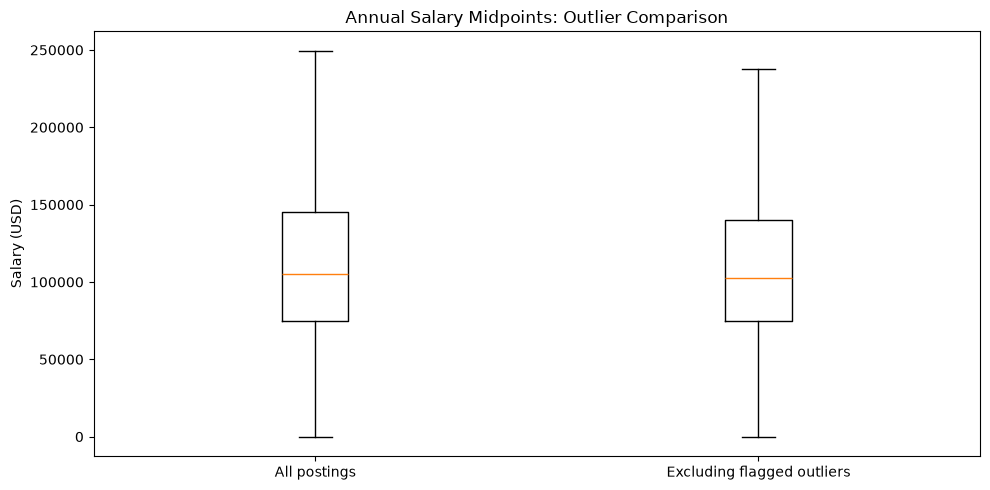

In [33]:

import matplotlib.pyplot as plt

salary_without_outliers = annual_salary.loc[
    ~annual_salary["salary_outlier_flag"],
    "salary_midpoint"
]

plt.figure(figsize=(10, 5))

plt.boxplot(
    [
        annual_salary["salary_midpoint"],
        salary_without_outliers
    ],
    tick_labels=["All postings", "Excluding flagged outliers"],
    showfliers=False
)

plt.title("Annual Salary Midpoints: Outlier Comparison")
plt.ylabel("Salary (USD)")
plt.tight_layout()
plt.show()


In [34]:

salary_comparison = pd.DataFrame({
    "All_Postings": annual_salary["salary_midpoint"].describe(),
    "Excluding_Outliers": salary_without_outliers.describe()
})

display(salary_comparison.round(2))

print(
    "Outlier percentage:",
    round(
        annual_salary["salary_outlier_flag"].mean() * 100, 2
    ),
    "%"
)


,All_Postings,Excluding_Outliers
count,19084.00,18462.00
mean,116350.46,109338.41
std,63070.20,47906.91
min,1.00,1.00
25%,75000.00,75000.00
50%,105000.00,102500.00
75%,144925.00,140000.00
max,875000.00,249550.00


Outlier percentage: 3.26 %


In [35]:

# Merge experience level into the annual salary subset
experience_salary = annual_salary[
    annual_salary["formatted_experience_level"].notna()
].copy()

# Summarize salary by experience level
experience_summary = (
    experience_salary
    .groupby("formatted_experience_level")
    .agg(
        Job_Count=("salary_midpoint", "count"),
        Median_Salary=("salary_midpoint", "median"),
        Mean_Salary=("salary_midpoint", "mean")
    )
    .sort_values("Median_Salary", ascending=False)
    .round(2)
)

display(experience_summary)


,Job_Count,Median_Salary,Mean_Salary
formatted_experience_level,,,
Executive,327,200000.0,210968.92
Director,1145,169500.0,174520.63
Mid-Senior level,7967,115000.0,123810.04
Associate,2119,82500.0,91191.38
Entry level,2803,77500.0,88284.45
Internship,43,65000.0,70335.18


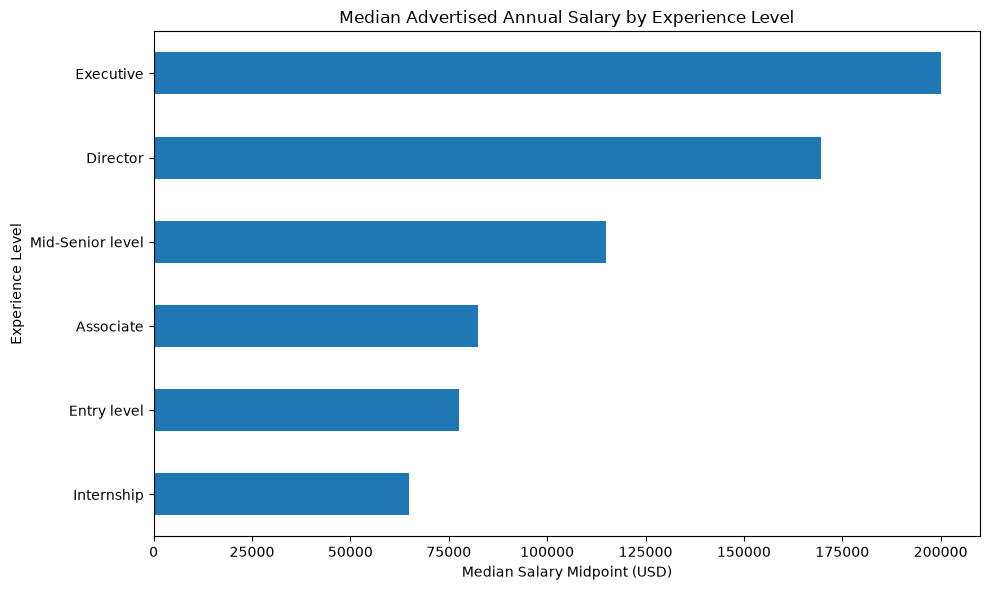

In [36]:

import matplotlib.pyplot as plt

experience_plot = experience_summary.sort_values("Median_Salary")

experience_plot["Median_Salary"].plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Median Advertised Annual Salary by Experience Level")
plt.xlabel("Median Salary Midpoint (USD)")
plt.ylabel("Experience Level")
plt.tight_layout()
plt.show()


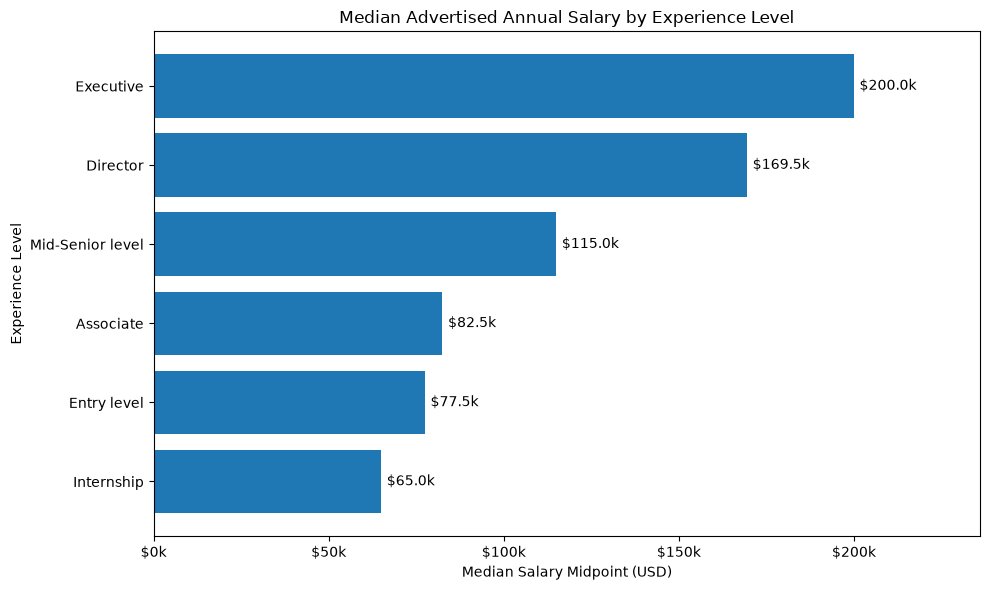

In [37]:

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

experience_plot = experience_summary.sort_values("Median_Salary")

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    experience_plot.index,
    experience_plot["Median_Salary"]
)

ax.set_title("Median Advertised Annual Salary by Experience Level")
ax.set_xlabel("Median Salary Midpoint (USD)")
ax.set_ylabel("Experience Level")

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x/1000:.0f}k")
)

ax.bar_label(
    bars,
    labels=[
        f"${value/1000:.1f}k"
        for value in experience_plot["Median_Salary"]
    ],
    padding=4
)

ax.set_xlim(
    0,
    experience_plot["Median_Salary"].max() * 1.18
)

plt.tight_layout()
plt.show()


In [38]:

top_paying_titles = (
    annual_salary
    .groupby("title")
    .agg(
        Job_Count=("salary_midpoint", "count"),
        Median_Salary=("salary_midpoint", "median")
    )
    .query("Job_Count >= 5")
    .sort_values("Median_Salary", ascending=False)
    .head(15)
)

display(top_paying_titles.round(2))


,Job_Count,Median_Salary
title,,
Oral Surgeon,6,625000.0
Chief Financial Officer,19,250000.0
Labor And Employment Attorney,8,250000.0
Psychiatrist,5,235000.0
Vice President Finance,8,225000.0
Medical Director,6,225000.0
Primary Care Physician,10,225000.0
Staff Software Engineer,6,220275.0
Head of Sales,10,218750.0


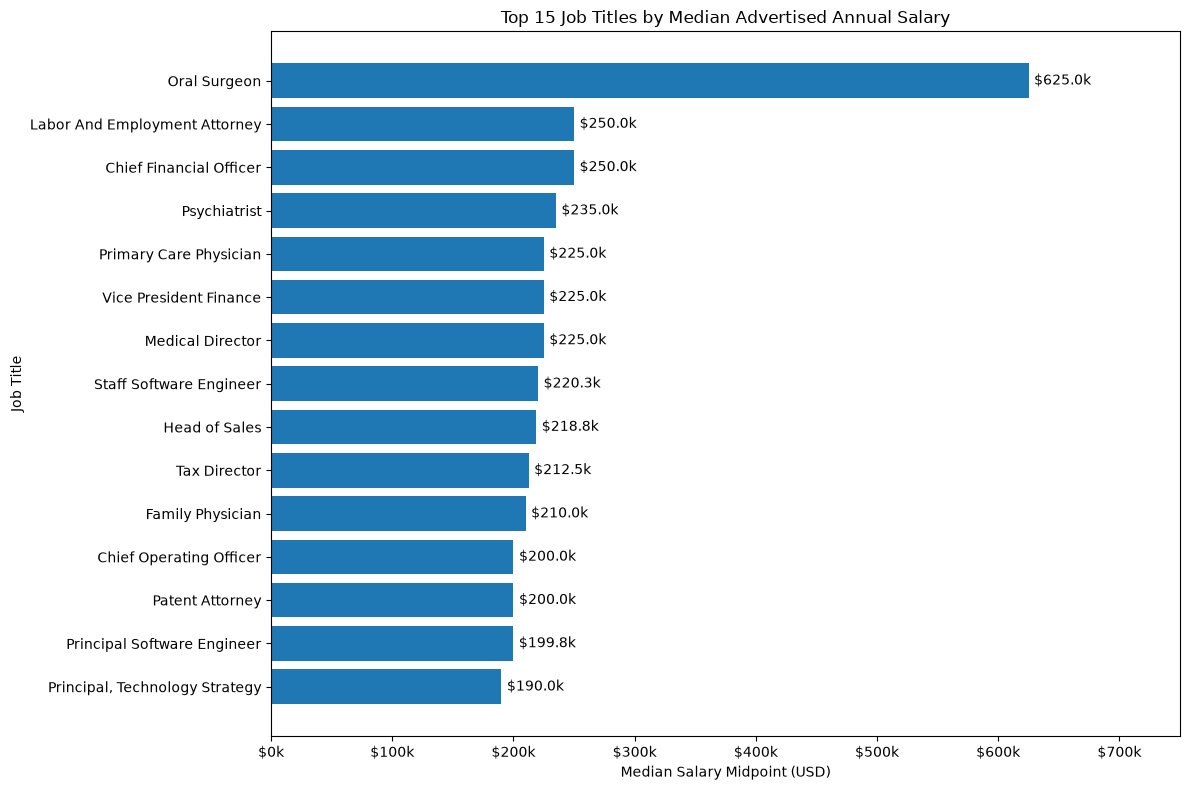

In [39]:

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Reverse order so the highest-paying title appears at the top
plot_data = top_paying_titles.sort_values("Median_Salary")

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    plot_data.index,
    plot_data["Median_Salary"]
)

ax.set_title("Top 15 Job Titles by Median Advertised Annual Salary")
ax.set_xlabel("Median Salary Midpoint (USD)")
ax.set_ylabel("Job Title")

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x/1000:.0f}k")
)

ax.bar_label(
    bars,
    labels=[
        f"${value/1000:.1f}k"
        for value in plot_data["Median_Salary"]
    ],
    padding=4
)

ax.set_xlim(0, plot_data["Median_Salary"].max() * 1.2)
plt.tight_layout()
plt.show()
